<a href="https://colab.research.google.com/github/chethan1428/ML2_Chethan_4NI23CI026/blob/main/candidate_elimination.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
X = [
    ['Sunny','Warm','Normal','Strong','Warm','Same'],
    ['Sunny','Warm','High','Strong','Warm','Same'],
    ['Rainy','Cold','High','Strong','Warm','Change'],
    ['Sunny','Warm','High','Strong','Cool','Change']
]
y = ['Yes','Yes','No','Yes']
attrs = ['Sky','AirTemp','Humidity','Wind','Water','Forecast']
n = len(attrs)

In [ ]:
def match(h, x):
    return all(a == '?' or a == b for a,b in zip(h,x))

def more_general(h1,h2):
    return all(a=='?' or a==b or b=='0' for a,b in zip(h1,h2))


def generalize(h,x):
    h=list(h)
    for i in range(n):
        if h[i]=='0': h[i]=x[i]
        elif h[i]!=x[i]: h[i]='?'
    return tuple(h)

def specialize(h,x,domains):
    out=[]
    for i in range(n):
        if h[i]=='?':
            for v in domains[i]:
                if v!=x[i]:
                    z=list(h); z[i]=v; out.append(tuple(z))
    return out

In [ ]:
def candidate_elimination(X,y):
    D=[set(x[i] for x in X) for i in range(n)]
    S=[tuple('0' for _ in range(n))]
    G=[tuple('?' for _ in range(n))]
    history=[(S.copy(),G.copy())]

    for x,label in zip(X,y):
        if label=='Yes':
            G=[g for g in G if match(g,x)]
            newS=[]
            for s in S:
                if match(s,x):
                    newS.append(s)
                else:
                    for h in [generalize(s,x)]:
                        if any(more_general(g,h) for g in G):
                            newS.append(h)
            S=list(set(newS))
        else:
            S=[s for s in S if not match(s,x)]
            newG=[]
            for g in G:
                if match(g,x):
                    for h in specialize(g,x,D):
                        if any(more_general(h,s) for s in S):
                            newG.append(h)
                else:
                    newG.append(g)
            G=list(set(newG))

        history.append((S.copy(),G.copy()))

        print(f"\nAfter Example {len(history)-1} ({label})")
        print("S:", S)
        print("G:", G)

    return S,G,history

In [ ]:
S,G,H = candidate_elimination(X,y)

print("\nFINAL S:",S)
print("FINAL G:",G)


After Example 1 (Yes)
S: [('Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same')]
G: [('?', '?', '?', '?', '?', '?')]

After Example 2 (Yes)
S: [('Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same')]
G: [('?', '?', '?', '?', '?', '?')]

After Example 3 (No)
S: [('Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same')]
G: [('?', '?', '?', '?', '?', 'Same'), ('?', 'Warm', '?', '?', '?', '?'), ('Sunny', '?', '?', '?', '?', '?')]

After Example 4 (Yes)
S: [('Sunny', 'Warm', '?', 'Strong', '?', '?')]
G: [('?', 'Warm', '?', '?', '?', '?'), ('Sunny', '?', '?', '?', '?', '?')]

FINAL S: [('Sunny', 'Warm', '?', 'Strong', '?', '?')]
FINAL G: [('?', 'Warm', '?', '?', '?', '?'), ('Sunny', '?', '?', '?', '?', '?')]


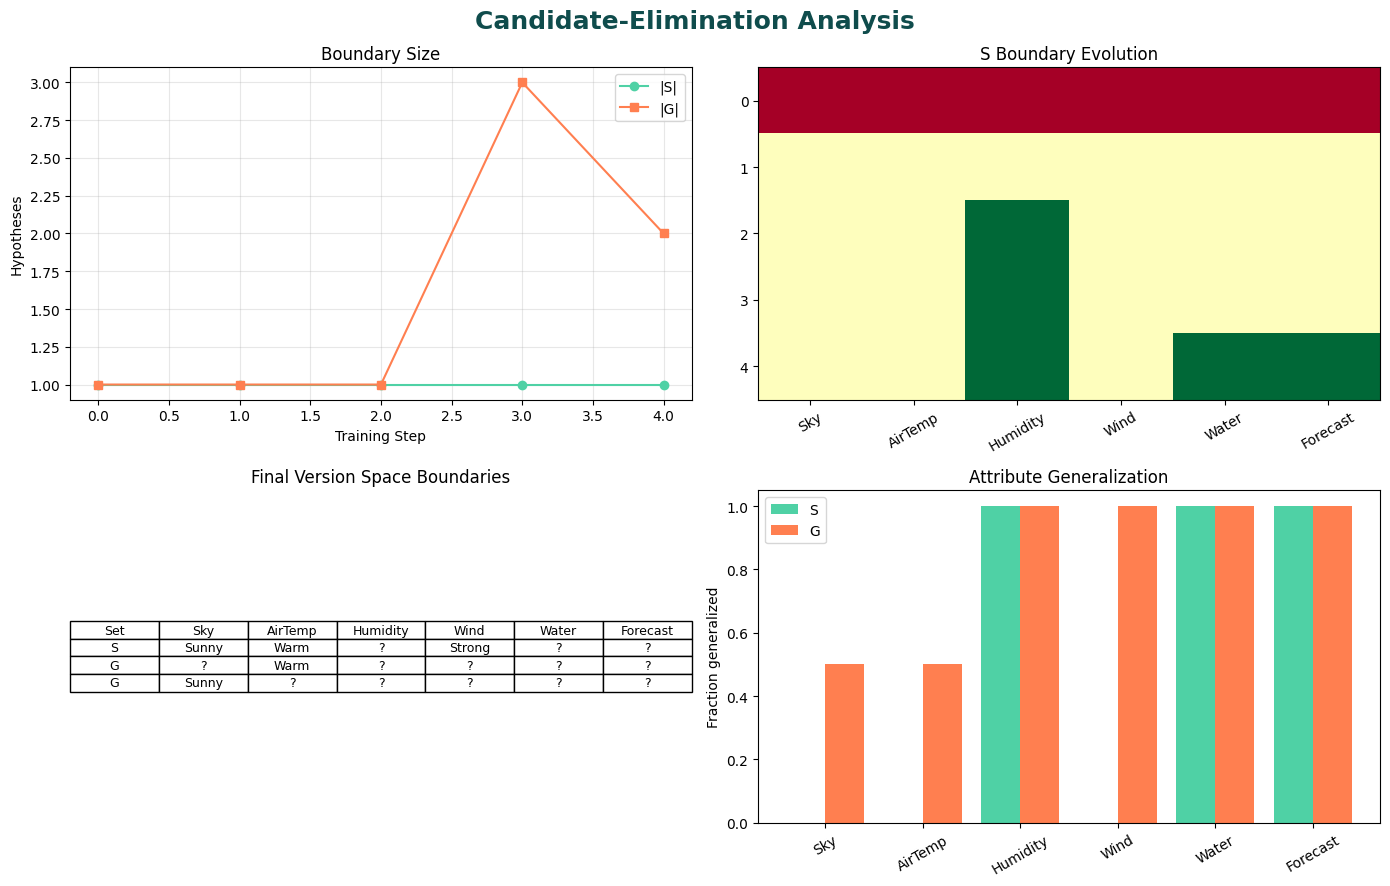

In [ ]:
teal='#0f4c4c'
mint='#4fd1a5'
orange='#ff7f50'

fig,ax=plt.subplots(2,2,figsize=(14,9))
fig.suptitle("Candidate-Elimination Analysis",fontsize=18,
             fontweight='bold',color=teal)

# 1. Boundary size
ax[0,0].plot(range(len(H)),[len(s) for s,g in H],
             'o-',color=mint,label='|S|')
ax[0,0].plot(range(len(H)),[len(g) for s,g in H],
             's-',color=orange,label='|G|')
ax[0,0].set_title("Boundary Size")
ax[0,0].set_xlabel("Training Step")
ax[0,0].set_ylabel("Hypotheses")
ax[0,0].legend()
ax[0,0].grid(alpha=.3)

# 2. S evolution
M=[]
for s,g in H:
    h=s[0] if s else ('0',)*n
    M.append([0 if v not in ['?','0'] else
              1 if v=='?' else -1 for v in h])

ax[0,1].imshow(M,cmap='RdYlGn',aspect='auto',vmin=-1,vmax=1)
ax[0,1].set_xticks(range(n))
ax[0,1].set_xticklabels(attrs,rotation=30)
ax[0,1].set_title("S Boundary Evolution")

# 3. Final boundaries
ax[1,0].axis('off')
rows=[['S']+list(s) for s in S]+[['G']+list(g) for g in G]
ax[1,0].table(cellText=rows,
              colLabels=['Set']+attrs,
              cellLoc='center',loc='center')
ax[1,0].set_title("Final Version Space Boundaries")

# 4. Generalization
sg = [np.mean([s[i] == '?' for s in S]) for i in range(n)]
gg = [np.mean([g[i] == '?' for g in G]) for i in range(n)]

x = np.arange(n)
ax[1,1].bar(x-.2, sg, .4, color=mint, label='S')
ax[1,1].bar(x+.2, gg, .4, color=orange, label='G')

ax[1,1].set_xticks(x)
ax[1,1].set_xticklabels(attrs, rotation=30)
ax[1,1].set_ylabel("Fraction generalized")
ax[1,1].set_title("Attribute Generalization")
ax[1,1].legend()

plt.tight_layout()
plt.savefig("candidate_elimination_analysis.png",dpi=150)
plt.show()